In [73]:
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split



# Data Load

In [74]:
df = pd.read_csv('/content/advertising.csv')
df

,TV,Radio,Newspaper,Sales
0,230.1,37.8,69.2,22.1
1,44.5,39.3,45.1,10.4
2,17.2,45.9,69.3,12.0
3,151.5,41.3,58.5,16.5
4,180.8,10.8,58.4,17.9
...,...,...,...,...
195,38.2,3.7,13.8,7.6
196,94.2,4.9,8.1,14.0
197,177.0,9.3,6.4,14.8
198,283.6,42.0,66.2,25.5


# Data Properties

In [75]:
df.shape

(200, 4)

In [76]:
df.dtypes

,0
TV,float64
Radio,float64
Newspaper,float64
Sales,float64


In [77]:
df.isna().sum()

,0
TV,0
Radio,0
Newspaper,0
Sales,0


In [78]:
df.describe()

,TV,Radio,Newspaper,Sales
count,200.000000,200.000000,200.000000,200.000000
mean,147.042500,23.264000,30.554000,15.130500
std,85.854236,14.846809,21.778621,5.283892
min,0.700000,0.000000,0.300000,1.600000
25%,74.375000,9.975000,12.750000,11.000000
50%,149.750000,22.900000,25.750000,16.000000
75%,218.825000,36.525000,45.100000,19.050000
max,296.400000,49.600000,114.000000,27.000000


# Feature Selection

In [79]:
df.corr()
#we can drop the columns if its -ve value

,TV,Radio,Newspaper,Sales
TV,1.000000,0.054809,0.056648,0.901208
Radio,0.054809,1.000000,0.354104,0.349631
Newspaper,0.056648,0.354104,1.000000,0.157960
Sales,0.901208,0.349631,0.157960,1.000000


<Axes: >

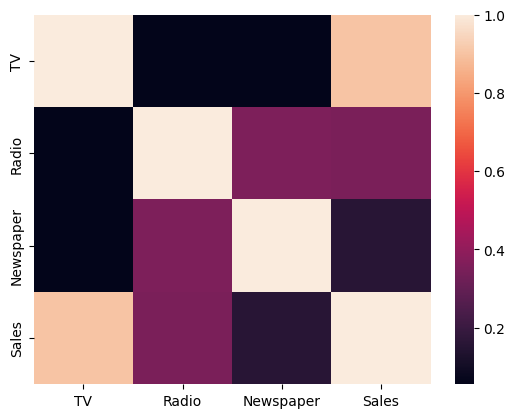

In [80]:
sns.heatmap(df.corr())

# Split features and labels

In [81]:
x =df.iloc[:,:-1]
y = df.iloc[:,-1]

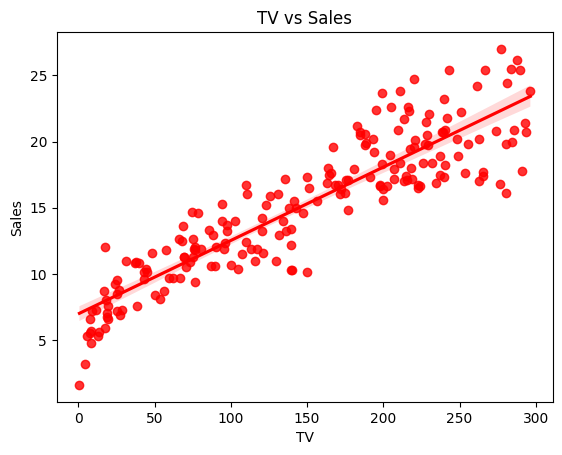

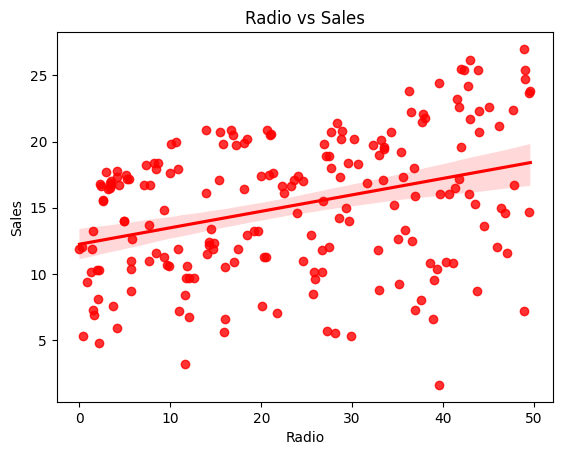

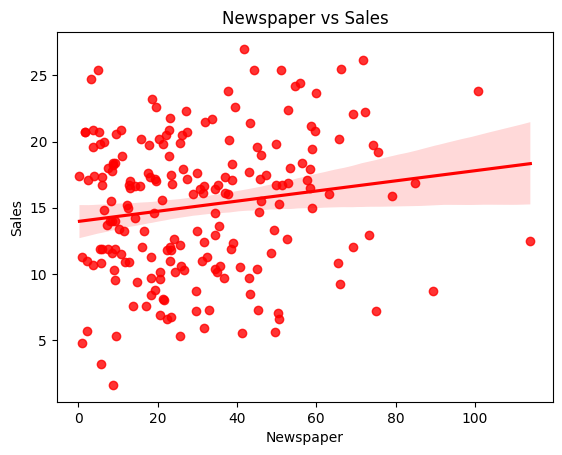

In [82]:
for i in x:
  sns.regplot(x=df[i],y=y,color='r')
  plt.title(f"{i} vs Sales")
  plt.show()

# Train Test Split

In [83]:
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=.33,random_state=42)

#Normalization

##**MinMax Scalar**

In min max scalr the values doesnt contain negative values. \
the values is between 0 and 1.
this works with min and max value .

In [84]:
from sklearn.preprocessing import MinMaxScaler # imporrt MInMaxScalar

In [85]:
scaler = MinMaxScaler()
x_train = scaler.fit_transform(x_train)
x_test = scaler.transform(x_test)


#Build Model

In [86]:
from sklearn.linear_model import LinearRegression

In [87]:
model = LinearRegression()
model.fit(x_train,y_train)

LinearRegression()

In [88]:
y_pred = model.predict(x_test)

In [89]:
y_pred

array([17.16807449, 20.5091305 , 23.73135731,  9.48459836, 21.58624062,
       12.76341388, 21.07612667,  8.79591649, 17.20467764, 16.72119979,
        8.97652259,  8.62700484, 18.42182115,  8.16102354, 12.72198768,
       15.01276938,  8.33546776, 17.87499103, 11.14052514, 20.4116162 ,
       20.9672174 , 13.01538836, 10.97713042, 22.52442657,  9.44900883,
        8.04519101, 20.86050789, 13.82515212, 10.87609343,  7.99397378,
       15.97284197, 10.72032118, 20.92393845, 10.79529851, 21.58216953,
       21.09152023, 12.17615116, 22.88913523, 12.61859879,  6.6010841 ,
       11.99190551, 15.30146497, 10.07089809,  9.55698762, 17.2102045 ,
        7.33269292, 10.52208395, 15.26836587, 11.26742672, 11.78599487,
       13.96969153, 14.66883212, 10.7619555 ,  9.51803749,  9.10445302,
       12.57686342, 10.55260009, 25.02632834,  8.00209792, 15.8239148 ,
       21.20319099, 17.02286072, 12.92029502, 10.11841929, 20.91220381,
        7.62205941])

In [90]:
y_test

,Sales
95,16.9
15,22.4
30,21.4
158,7.3
128,24.7
...,...
97,20.5
31,11.9
12,9.2
35,17.8


# Model properties

### Model Slope

In [91]:

print(model.coef_)

[15.90486704  4.97382564  0.79458386]


### Intercept

In [92]:
print(model.intercept_)

4.838013540953378


## Predict a values

In [93]:
print(model.predict(scaler.transform([[38.2,3.7,13.8]])))

[7.33269292]


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but MinMaxScaler was fitted with feature names
  warnings.warn(


## Difference from actual value

In [94]:
df1 = pd.DataFrame({'actual value':y_test,'predict value':y_pred,'difference:':y_pred-y_test})
df1

,actual value,predict value,difference:
95,16.9,17.168074,0.268074
15,22.4,20.509131,-1.890869
30,21.4,23.731357,2.331357
158,7.3,9.484598,2.184598
128,24.7,21.586241,-3.113759
...,...,...,...
97,20.5,17.022861,-3.477139
31,11.9,12.920295,1.020295
12,9.2,10.118419,0.918419
35,17.8,20.912204,3.112204


# Evaluation

In [95]:
from sklearn.metrics import mean_absolute_error,mean_absolute_percentage_error,mean_squared_error,root_mean_squared_error,r2_score

In [96]:
mae = mean_absolute_error(y_test,y_pred)
mape = mean_absolute_percentage_error(y_test,y_pred)
mse = mean_squared_error(y_test,y_pred)
rmse = root_mean_squared_error(y_test,y_pred)
r2 = r2_score(y_test,y_pred)


print('mae :',mae)
print('mape :',mape)
print('mse :',mse)
print('rmse :',rmse)
print('R2 Score :',r2)

mae : 1.2220332104204168
mape : 0.10689303103443297
mse : 2.722866082025962
rmse : 1.6501109302183177
R2 Score : 0.9031541781049792
